In [5]:
from pathlib import Path

# The main folder of the project.
# The r before the quotes makes it a "raw string", so Windows backslashes (\)
# are treated as normal characters and not as special escape codes.
project_path = Path(
    r"C:\Users\ACER\Documents\AI-Project-Road-classifire-"
)

# The two class folders, built by joining the project path with a folder name.
broken_path = project_path / "Broken"
not_broken_path = project_path / "Not_Broken"

# .exists() returns True if the path is real, otherwise False.
print("Project folder exists:     ", project_path.exists())
print("Broken folder exists:      ", broken_path.exists())
print("Not_Broken folder exists:  ", not_broken_path.exists())

# Count the files directly inside each folder.
# .iterdir() lists everything in a folder; .is_file() keeps only files (not subfolders).
if broken_path.exists():
    broken_count = len([f for f in broken_path.iterdir() if f.is_file()])
    print("Files in Broken:           ", broken_count)

if not_broken_path.exists():
    not_broken_count = len([f for f in not_broken_path.iterdir() if f.is_file()])
    print("Files in Not_Broken:       ", not_broken_count)

Project folder exists:      True
Broken folder exists:       True
Not_Broken folder exists:   True
Files in Broken:            110
Files in Not_Broken:        94


In [7]:
import sys

print("Python executable:", sys.executable)
print("Python version:   ", sys.version)

Python executable: c:\Users\ACER\Documents\AI-Project-Road-classifire-\venv\Scripts\python.exe
Python version:    3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]


In [8]:
import importlib

# Names used when importing, mapped to a friendly label.
libraries = ["tensorflow", "numpy", "matplotlib", "PIL", "sklearn"]

for name in libraries:
    try:
        module = importlib.import_module(name)
        version = getattr(module, "__version__", "version unknown")
        print(f"[OK]      {name:12} version {version}")
    except ImportError:
        print(f"[MISSING] {name:12} is NOT installed in this environment")

[OK]      tensorflow   version 2.21.0
[OK]      numpy        version 2.2.6
[OK]      matplotlib   version 3.10.9
[OK]      PIL          version 12.3.0
[OK]      sklearn      version 1.7.2


In [9]:
from collections import Counter

# Extensions are compared in lowercase, so ".JPG" and ".jpg" count as the same type.
def count_extensions(folder):
    extensions = [f.suffix.lower() for f in folder.iterdir() if f.is_file()]
    return Counter(extensions)

print("Broken folder:")
for ext, count in count_extensions(broken_path).items():
    print(f"   {ext:10} {count}")

print("\nNot_Broken folder:")
for ext, count in count_extensions(not_broken_path).items():
    print(f"   {ext:10} {count}")

Broken folder:
   .jpg       110

Not_Broken folder:
   .jpg       94


In [10]:
def show_sample_names(folder, how_many=5):
    names = sorted([f.name for f in folder.iterdir() if f.is_file()])
    for name in names[:how_many]:
        print("   ", name)

print("Broken (first 5 files):")
show_sample_names(broken_path)

print("\nNot_Broken (first 5 files):")
show_sample_names(not_broken_path)

Broken (first 5 files):
    broken_1.jpg
    broken_10.jpg
    broken_100.jpg
    broken_101.jpg
    broken_102.jpg

Not_Broken (first 5 files):
    not_broken_1.jpg
    not_broken_10.jpg
    not_broken_11.jpg
    not_broken_12.jpg
    not_broken_13.jpg


In [11]:
from PIL import Image

def inspect_folder(folder):
    sizes = []         # (width, height) of each readable image
    modes = []         # color mode of each readable image
    bad_files = []     # (filename, error message) for each unreadable image

    for file in sorted(folder.iterdir()):
        if not file.is_file():
            continue
        try:
            with Image.open(file) as img:
                img.load()   # forces Pillow to read the whole file, not just the header
                sizes.append(img.size)
                modes.append(img.mode)
        except Exception as error:
            bad_files.append((file.name, str(error)))

    return sizes, modes, bad_files


for class_name, folder in [("Broken", broken_path), ("Not_Broken", not_broken_path)]:
    sizes, modes, bad_files = inspect_folder(folder)

    widths = [s[0] for s in sizes]
    heights = [s[1] for s in sizes]

    print(f"=== {class_name} ===")
    print("Readable images:  ", len(sizes))
    print("Unreadable images:", len(bad_files))
    print("Color modes:      ", dict(Counter(modes)))
    print("Width  min/max:   ", min(widths), "/", max(widths))
    print("Height min/max:   ", min(heights), "/", max(heights))
    print("Different sizes:  ", len(set(sizes)))

    for name, message in bad_files:
        print("   PROBLEM FILE:", name, "->", message)
    print()

=== Broken ===
Readable images:   110
Unreadable images: 0
Color modes:       {'RGB': 110}
Width  min/max:    960 / 1200
Height min/max:    1280 / 1600
Different sizes:   2

=== Not_Broken ===
Readable images:   94
Unreadable images: 0
Color modes:       {'RGB': 94}
Width  min/max:    960 / 1200
Height min/max:    1280 / 1600
Different sizes:   2



In [12]:
def count_exact_sizes(folder):
    sizes = []
    for file in sorted(folder.iterdir()):
        if file.is_file():
            with Image.open(file) as img:
                sizes.append(img.size)   # (width, height)
    return Counter(sizes)

for class_name, folder in [("Broken", broken_path), ("Not_Broken", not_broken_path)]:
    print(f"=== {class_name} ===")
    for (width, height), count in count_exact_sizes(folder).items():
        print(f"   {width} x {height}  ->  {count} images")
    print()
    

=== Broken ===
   1200 x 1600  ->  88 images
   960 x 1280  ->  22 images

=== Not_Broken ===
   960 x 1280  ->  48 images
   1200 x 1600  ->  46 images



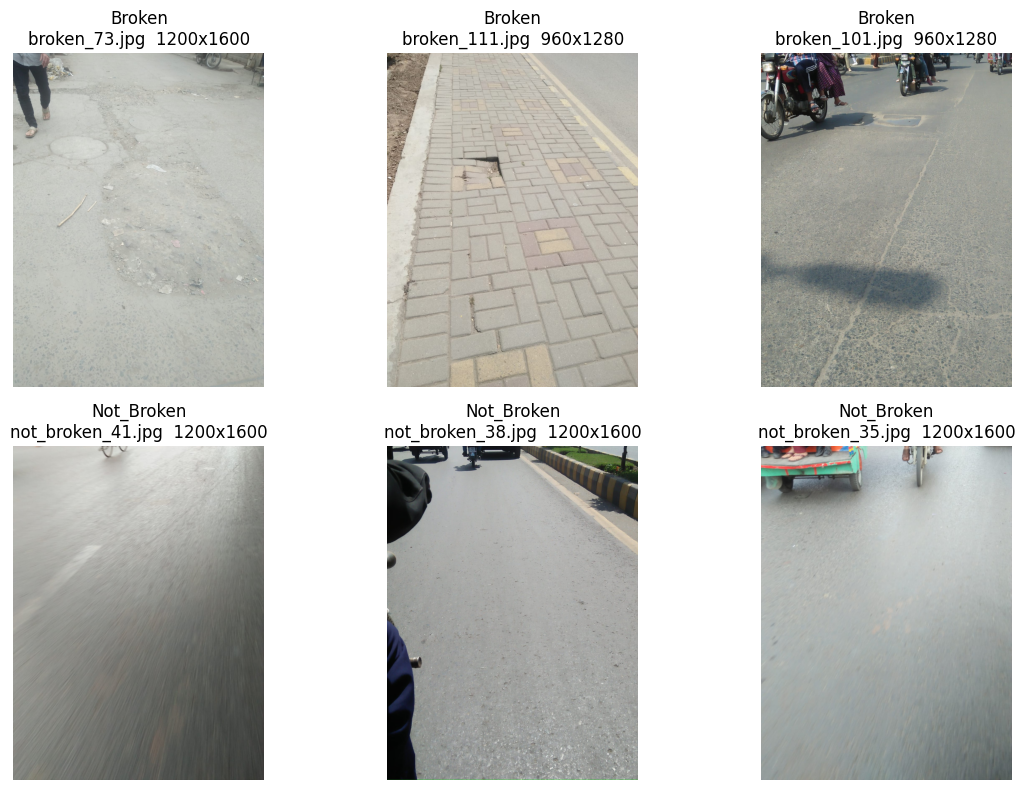

In [13]:
import random
import matplotlib.pyplot as plt

random.seed(42)   # fixed seed: the same "random" images appear every time

broken_files = sorted([f for f in broken_path.iterdir() if f.is_file()])
not_broken_files = sorted([f for f in not_broken_path.iterdir() if f.is_file()])

samples = (
    [(f, "Broken") for f in random.sample(broken_files, 3)]
    + [(f, "Not_Broken") for f in random.sample(not_broken_files, 3)]
)

plt.figure(figsize=(12, 8))
for i, (file, label) in enumerate(samples):
    with Image.open(file) as img:
        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(f"{label}\n{file.name}  {img.size[0]}x{img.size[1]}")
        plt.axis("off")
plt.tight_layout()
plt.show()

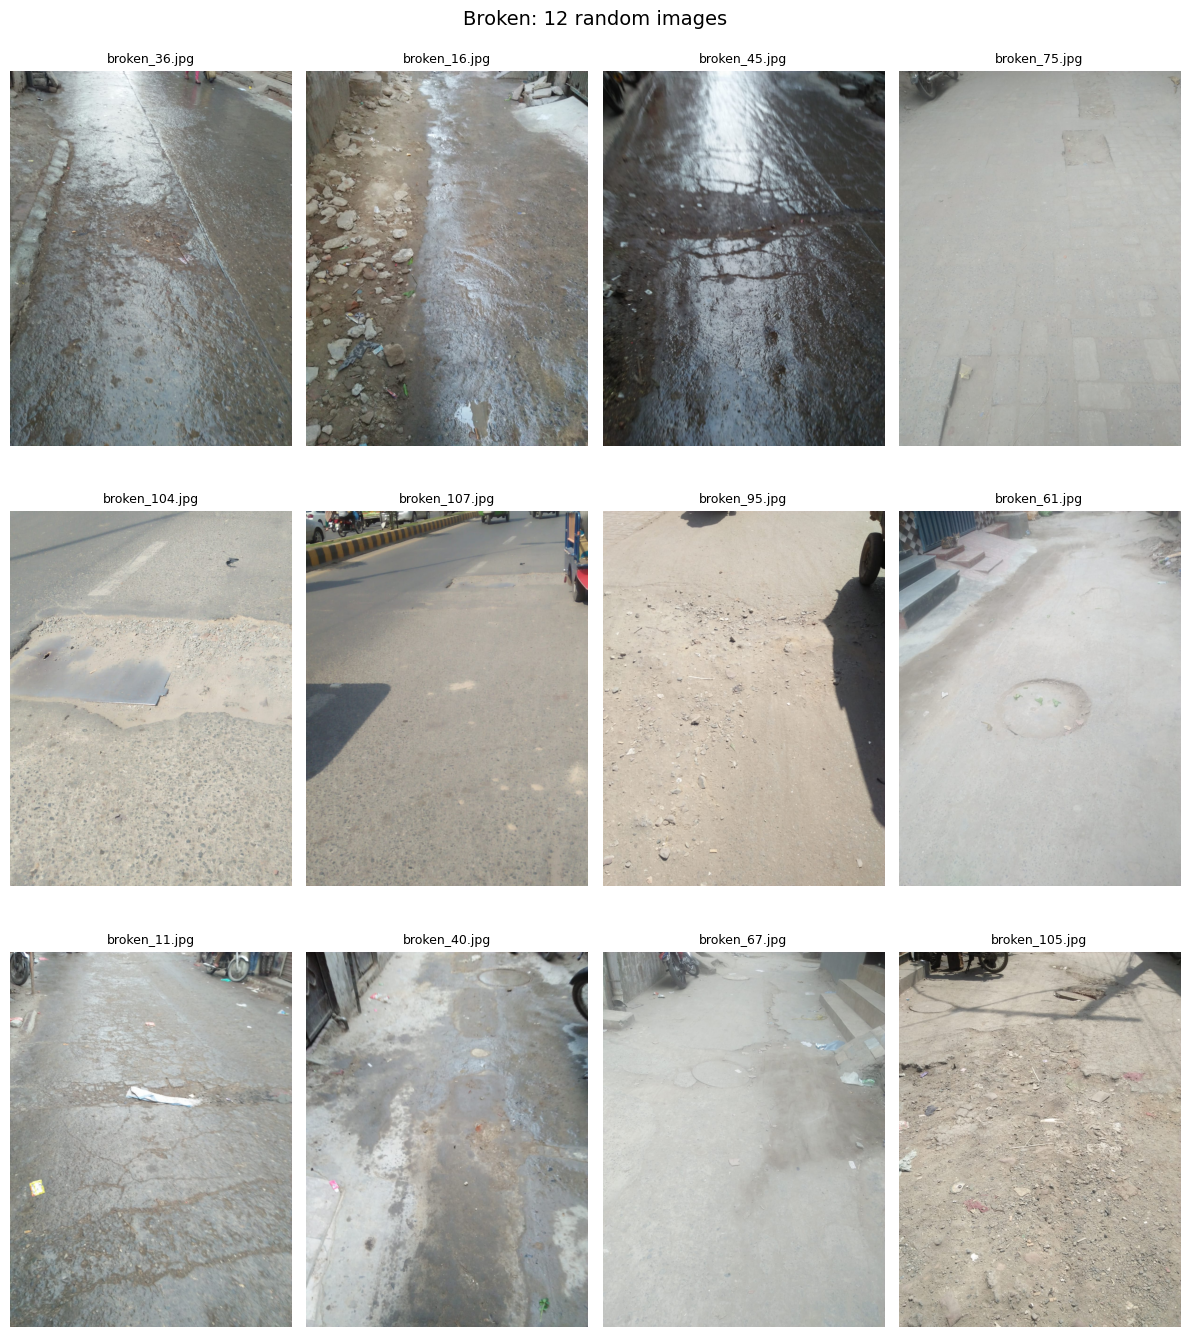

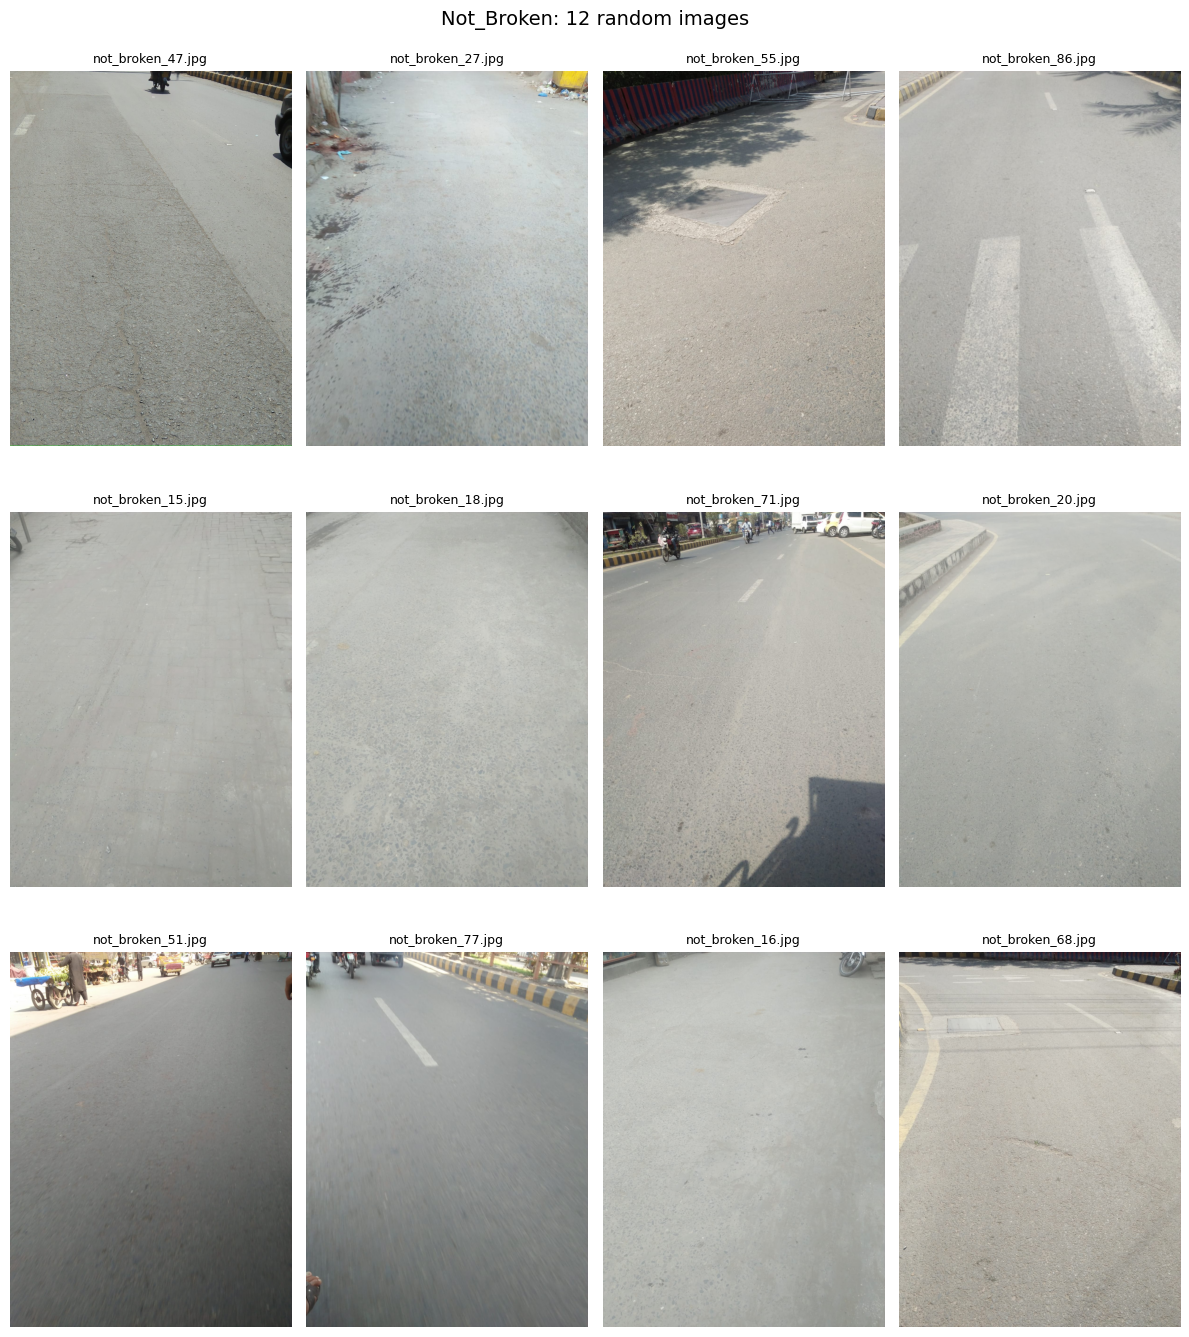

In [14]:
def show_grid(files, title, rows=3, cols=4, seed=7):
    random.seed(seed)
    chosen = random.sample(files, rows * cols)
    plt.figure(figsize=(12, 14))
    for i, file in enumerate(chosen):
        with Image.open(file) as img:
            plt.subplot(rows, cols, i + 1)
            plt.imshow(img)
            plt.title(file.name, fontsize=9)
            plt.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_grid(broken_files, "Broken: 12 random images")
show_grid(not_broken_files, "Not_Broken: 12 random images")

In [15]:
import hashlib

# Combine both classes into one list of (file path, label).
all_files = (
    [(f, "Broken") for f in broken_files]
    + [(f, "Not_Broken") for f in not_broken_files]
)
print("Total files:", len(all_files))

hash_groups = {}   # fingerprint -> list of (filename, label)

for file, label in all_files:
    fingerprint = hashlib.sha256(file.read_bytes()).hexdigest()
    hash_groups.setdefault(fingerprint, []).append((file.name, label))

exact_duplicates = {h: g for h, g in hash_groups.items() if len(g) > 1}

print("Unique fingerprints:", len(hash_groups))
print("Groups of exact duplicates:", len(exact_duplicates))
for group in exact_duplicates.values():
    print("   ", group)

Total files: 204
Unique fingerprints: 202
Groups of exact duplicates: 2
    [('not_broken_24.jpg', 'Not_Broken'), ('not_broken_25.jpg', 'Not_Broken')]
    [('not_broken_30.jpg', 'Not_Broken'), ('not_broken_34.jpg', 'Not_Broken')]


In [16]:
import numpy as np

def dhash(file, hash_size=8):
    with Image.open(file) as img:
        small = img.convert("L").resize(
            (hash_size + 1, hash_size), Image.Resampling.LANCZOS
        )
        pixels = np.asarray(small, dtype=np.int16)
    return (pixels[:, 1:] > pixels[:, :-1]).flatten()

hashes = [dhash(file) for file, label in all_files]

similar_pairs = []
for i in range(len(all_files)):
    for j in range(i + 1, len(all_files)):
        distance = int(np.count_nonzero(hashes[i] != hashes[j]))
        if distance <= 10:
            similar_pairs.append((distance, i, j))

similar_pairs.sort()
print("Pairs with distance <= 10:", len(similar_pairs))

for distance, i, j in similar_pairs[:20]:
    name_i, label_i = all_files[i][0].name, all_files[i][1]
    name_j, label_j = all_files[j][0].name, all_files[j][1]
    print(f"distance {distance:2}:  {name_i} ({label_i})  <->  {name_j} ({label_j})")

Pairs with distance <= 10: 209
distance  0:  not_broken_24.jpg (Not_Broken)  <->  not_broken_25.jpg (Not_Broken)
distance  0:  not_broken_30.jpg (Not_Broken)  <->  not_broken_34.jpg (Not_Broken)
distance  3:  broken_99.jpg (Broken)  <->  not_broken_51.jpg (Not_Broken)
distance  3:  not_broken_51.jpg (Not_Broken)  <->  not_broken_58.jpg (Not_Broken)
distance  3:  not_broken_58.jpg (Not_Broken)  <->  not_broken_65.jpg (Not_Broken)
distance  4:  broken_106.jpg (Broken)  <->  not_broken_58.jpg (Not_Broken)
distance  4:  broken_106.jpg (Broken)  <->  not_broken_90.jpg (Not_Broken)
distance  4:  broken_106.jpg (Broken)  <->  not_broken_94.jpg (Not_Broken)
distance  4:  not_broken_41.jpg (Not_Broken)  <->  not_broken_57.jpg (Not_Broken)
distance  4:  not_broken_46.jpg (Not_Broken)  <->  not_broken_48.jpg (Not_Broken)
distance  4:  not_broken_51.jpg (Not_Broken)  <->  not_broken_65.jpg (Not_Broken)
distance  4:  not_broken_72.jpg (Not_Broken)  <->  not_broken_94.jpg (Not_Broken)
distance  5:  

In [17]:
all_distances = []
for i in range(len(all_files)):
    for j in range(i + 1, len(all_files)):
        d = int(np.count_nonzero(hashes[i] != hashes[j]))
        all_distances.append(d)

for limit in [0, 2, 4, 6, 8, 10]:
    count = sum(1 for d in all_distances if d <= limit)
    print(f"distance <= {limit:2}:  {count} pairs")

distance <=  0:  2 pairs
distance <=  2:  2 pairs
distance <=  4:  12 pairs
distance <=  6:  41 pairs
distance <=  8:  110 pairs
distance <= 10:  209 pairs


Close pairs (distance <= 4): 12


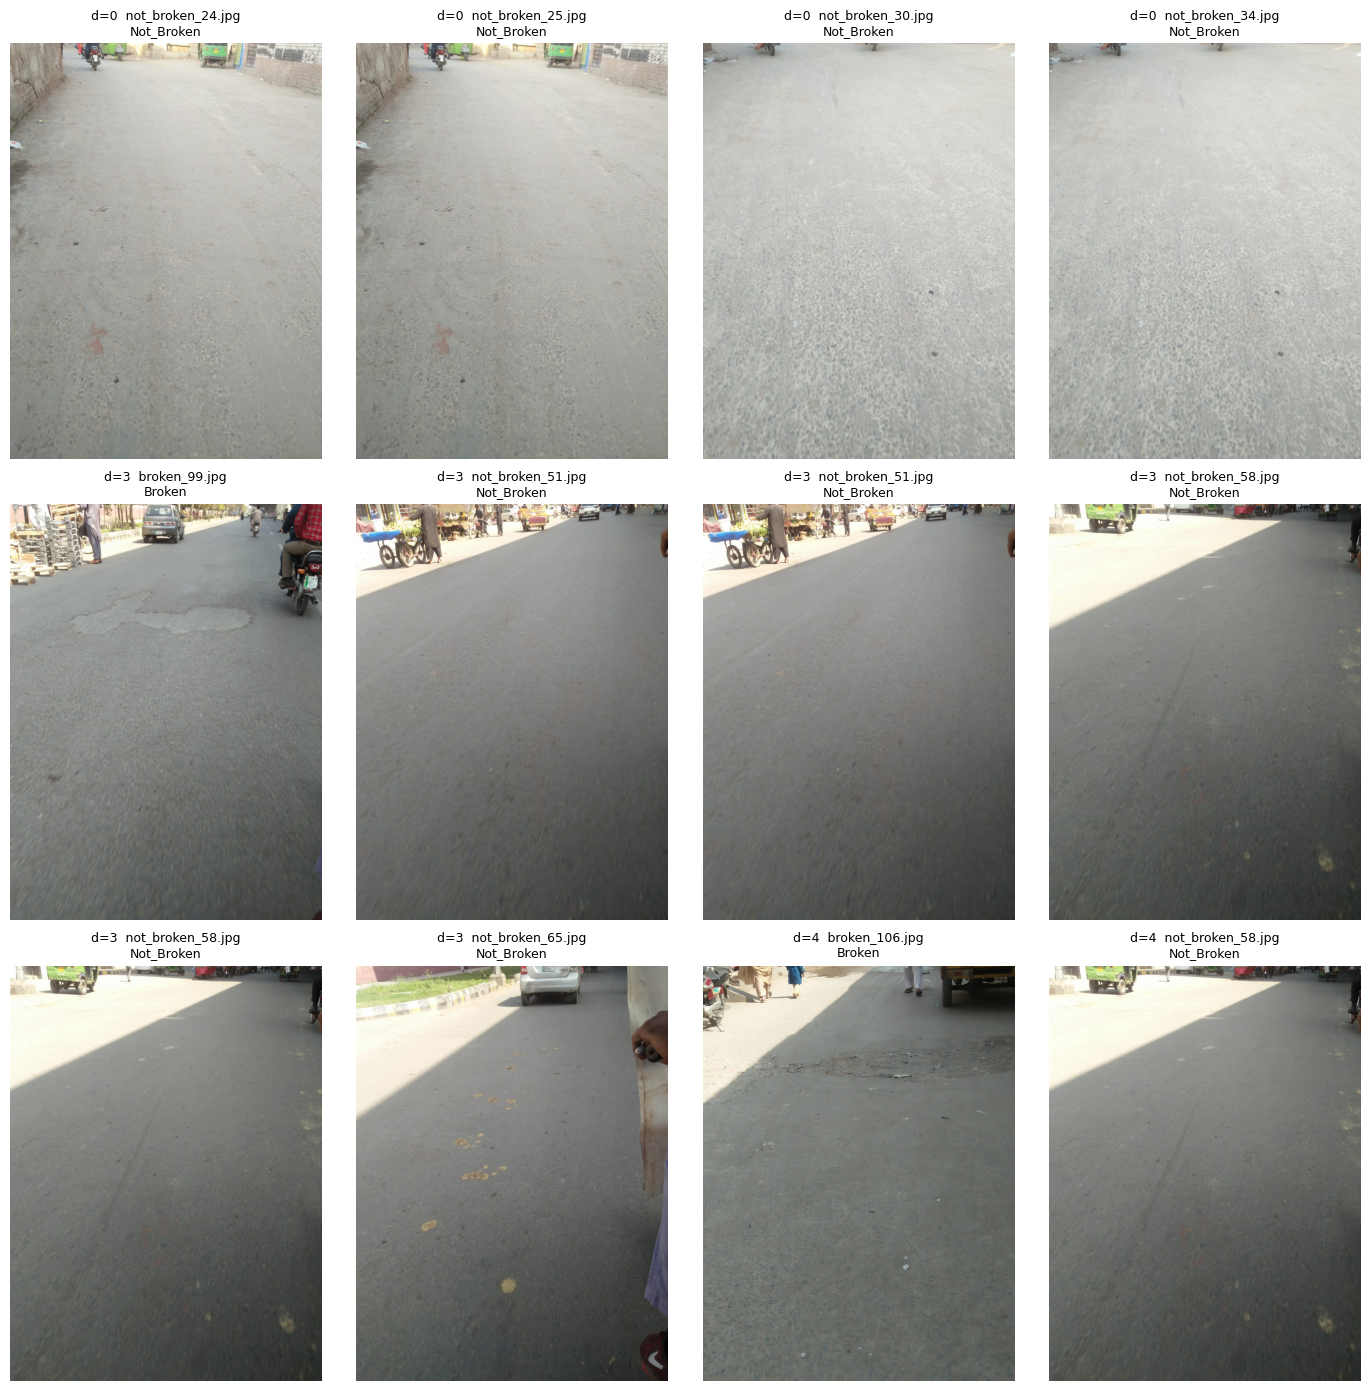

In [18]:
# Keep only the pairs whose fingerprints differ by 4 bits or fewer.
close_pairs = [p for p in similar_pairs if p[0] <= 4]
print("Close pairs (distance <= 4):", len(close_pairs))

# Show 6 pairs at a time. Later, change [0:6] to [6:12] to see the rest.
pairs_to_show = close_pairs[0:6]

plt.figure(figsize=(14, 14))
for k, (distance, i, j) in enumerate(pairs_to_show):
    for m, index in enumerate((i, j)):
        file, label = all_files[index]
        # 3 rows x 4 columns: each row holds two pairs (4 images).
        position = 4 * (k // 2) + 2 * (k % 2) + m + 1
        plt.subplot(3, 4, position)
        with Image.open(file) as img:
            plt.imshow(img)
        plt.title(f"d={distance}  {file.name}\n{label}", fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()